# Car Price Prediction with Machine Learning

## 1. Project Introduction

### Objective

The objective of this project is to develop a machine learning regression model that predicts the selling price of a used car based on its characteristics.

### Dataset

We use the Vehicle Dataset from CarDekho, containing 301 records and 9 columns. It includes information about car names, manufacturing years, selling prices, present showroom prices, kilometers driven, fuel types, seller types, transmission types, and previous owners.

### Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

### Machine Learning Approach

This is a supervised machine learning regression problem.

We will train and compare Linear Regression and Random Forest Regression models to predict used car selling prices.

The target variable is `Selling_Price`.

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model saving
import joblib

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In this section, we load the CarDekho dataset using Pandas.

We will inspect the first few records to understand the structure and contents of the dataset.

In [4]:
# Load dataset
df = pd.read_csv("../data/car_data.csv")

# Display first five records
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Initial Data Exploration

Before preprocessing, we need to understand the dataset.

We will examine:
- Dataset dimensions
- Column names
- Data types
- Statistical summaries

This helps us understand what information is available and identify potential data quality issues.

In [5]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
df.info()

Dataset shape: (301, 9)

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [6]:
# Statistical summary
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [7]:
# Check categorical columns
df.describe(include="object")

,Car_Name,Fuel_Type,Seller_Type,Transmission
count,301,301,301,301
unique,98,3,2,2
top,city,Petrol,Dealer,Manual
freq,26,239,195,261


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, distributions, and relationships within the dataset.

We will investigate:
- Missing values
- Duplicate records
- Selling price distribution
- Numerical feature distributions
- Categorical feature distributions
- Relationships between features and selling price

In [8]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [9]:
# Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 2


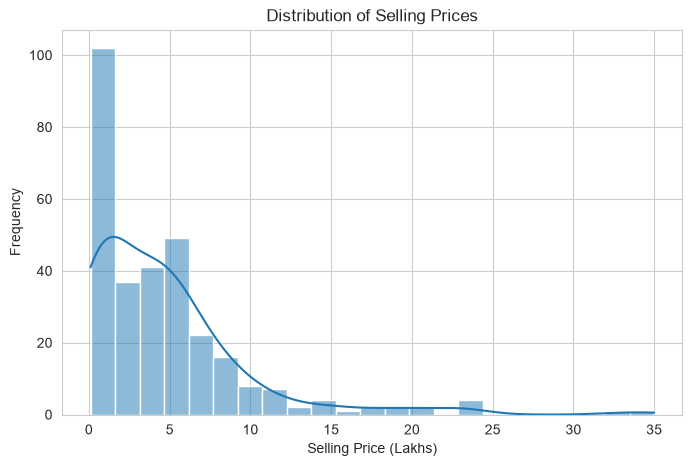

In [10]:
# Target variable distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], kde=True)

plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price (Lakhs)")
plt.ylabel("Frequency")

plt.show()

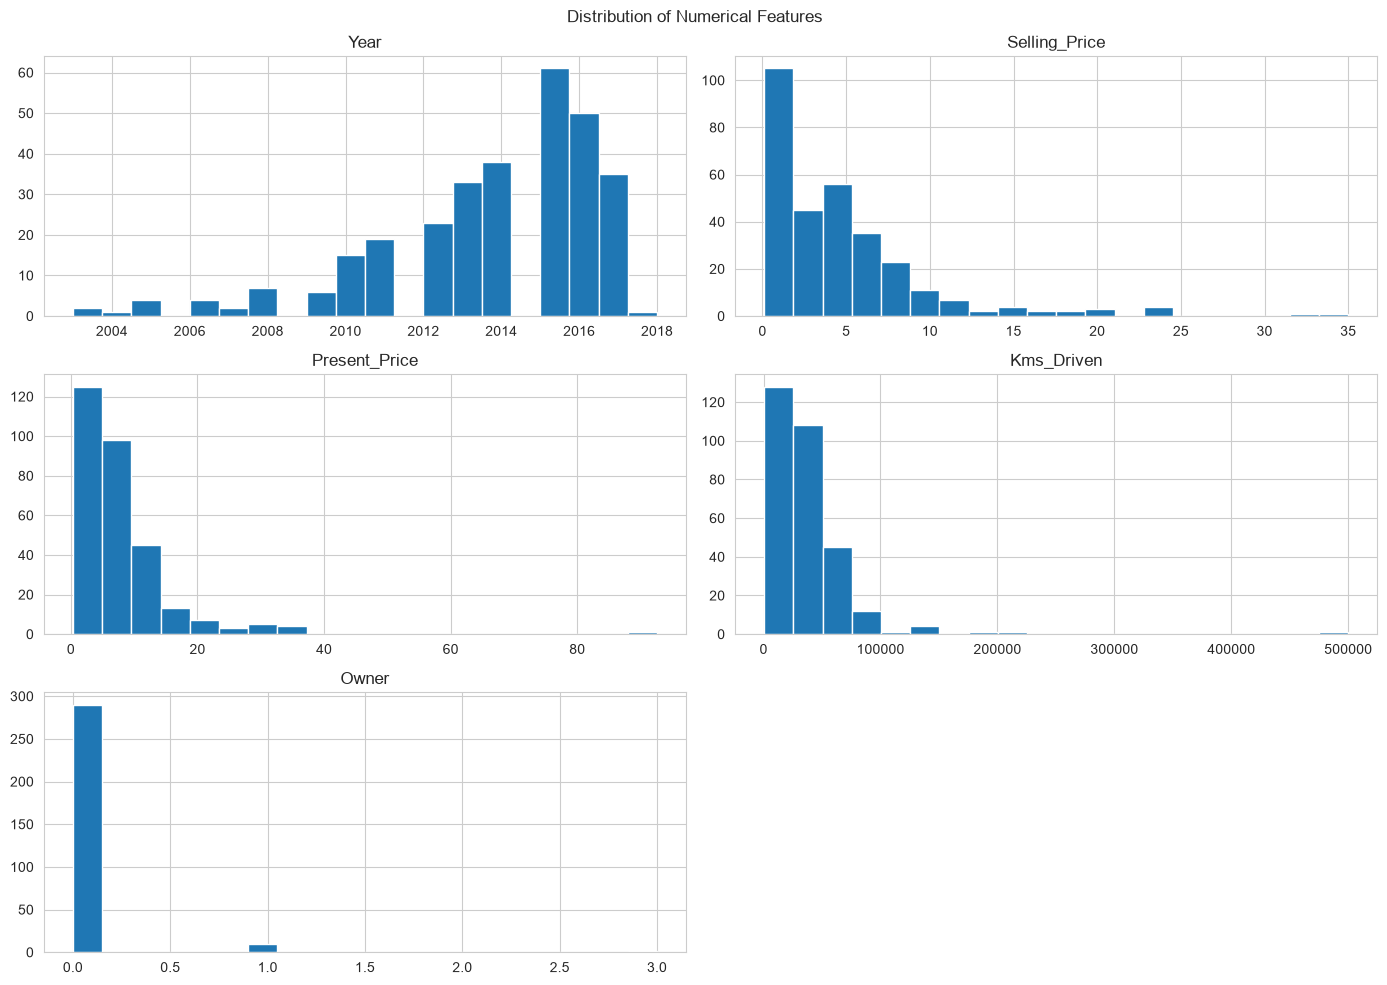

In [11]:
# Numerical feature distributions
df.hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()

plt.show()

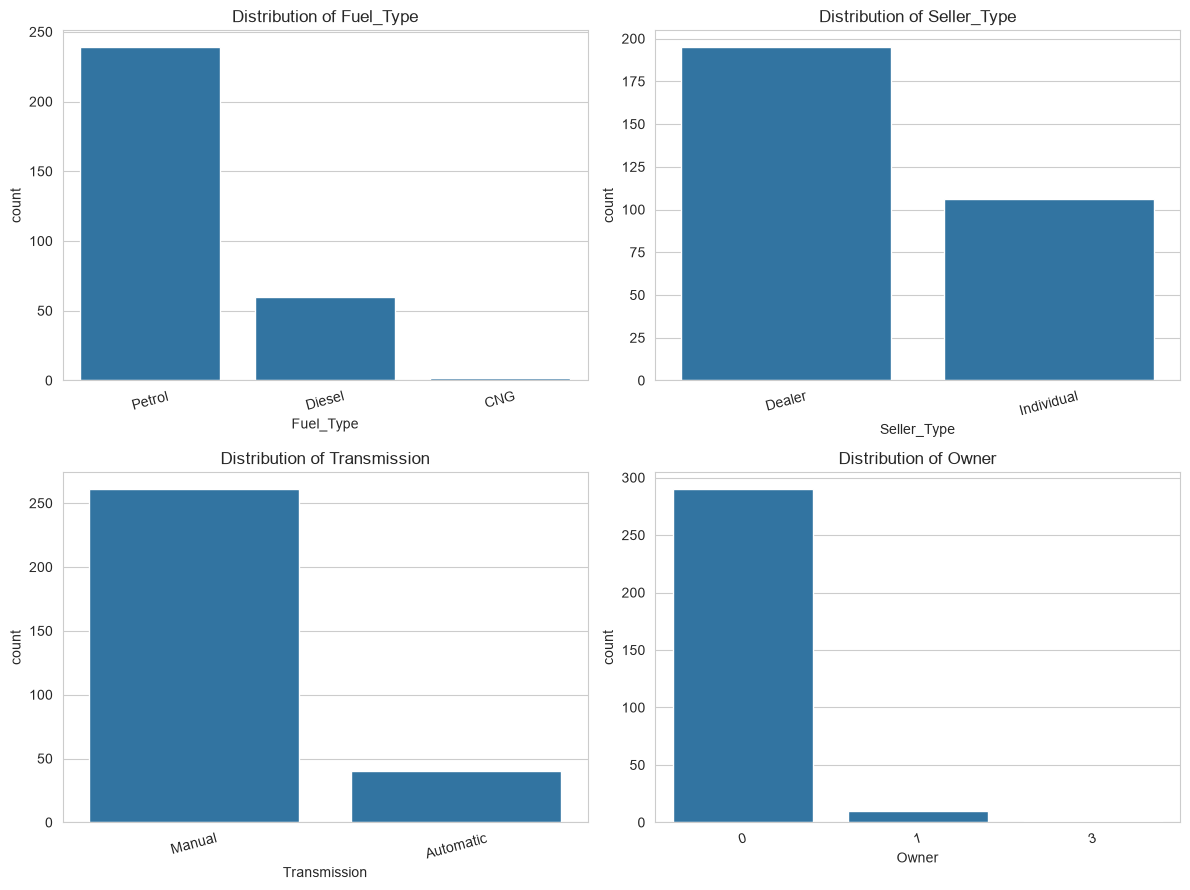

In [12]:
# Categorical feature distributions
categorical_columns = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission",
    "Owner"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for column, ax in zip(categorical_columns, axes.flatten()):
    sns.countplot(data=df, x=column, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 5. Data Cleaning

Data cleaning ensures that the dataset is suitable for machine learning.

In this section, we will:
- Remove exact duplicate records.
- Check missing values.
- Verify data types.
- Confirm that the target variable contains valid values.

We will avoid removing outliers without understanding whether they represent genuine observations.

In [13]:
# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Check missing values again
print("Missing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check dataset dimensions after cleaning
print("\nDataset shape after cleaning:", df.shape)

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Data types:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

Dataset shape after cleaning: (299, 9)


## 6. Feature Engineering

Feature engineering involves creating useful features from existing data.

We will make two improvements:

1. Extract the car brand from `Car_Name` because different manufacturers may have different pricing patterns.
2. Create a `Car_Age` feature using the manufacturing year.

The original `Car_Name` column will be removed after extracting the brand to avoid having too many individual car names as categorical features.

We will also remove the original `Year` column after creating `Car_Age`.

In [14]:
# Extract car brand from car name
df["Brand"] = df["Car_Name"].str.split().str[0]

# Calculate car age relative to the dataset period
reference_year = df["Year"].max() + 1

df["Car_Age"] = reference_year - df["Year"]

# Remove original columns
df.drop(columns=["Car_Name", "Year"], inplace=True)

# Display updated dataset
df.head()

,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,ritz,5
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,sx4,6
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,ciaz,2
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,wagon,8
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,swift,5


In [15]:
# Check updated dataset information
print("Reference year:", reference_year)

print("\nUpdated dataset shape:", df.shape)

df.info()

Reference year: 2019

Updated dataset shape: (299, 9)
<class 'pandas.DataFrame'>
Index: 299 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Selling_Price  299 non-null    float64
 1   Present_Price  299 non-null    float64
 2   Kms_Driven     299 non-null    int64  
 3   Fuel_Type      299 non-null    str    
 4   Seller_Type    299 non-null    str    
 5   Transmission   299 non-null    str    
 6   Owner          299 non-null    int64  
 7   Brand          299 non-null    object 
 8   Car_Age        299 non-null    int64  
dtypes: float64(2), int64(3), object(1), str(3)
memory usage: 23.4+ KB


## 7. Data Visualization

Visualizations help us understand how different car characteristics relate to selling prices.

We will explore:
- Correlation between numerical features.
- Selling price versus present price.
- Selling price versus car age.
- Selling price across fuel types.
- Selling price across transmission types.

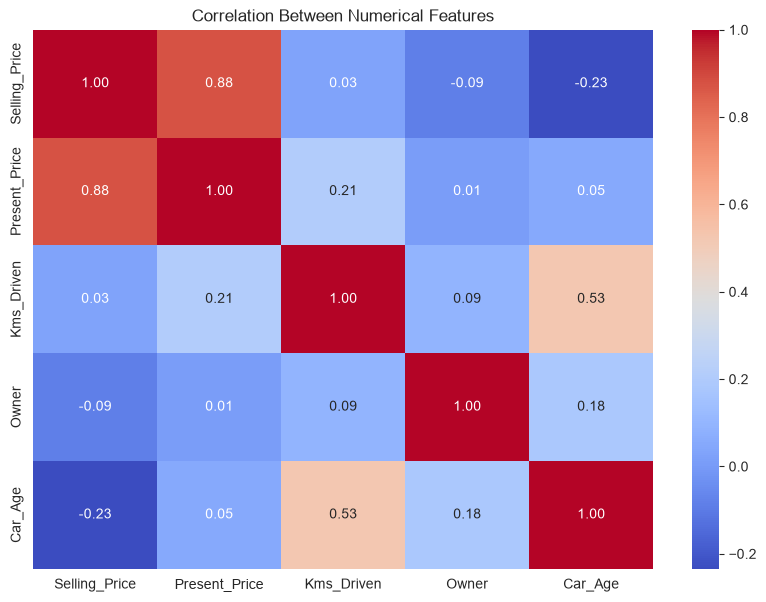

In [16]:
# Correlation heatmap
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

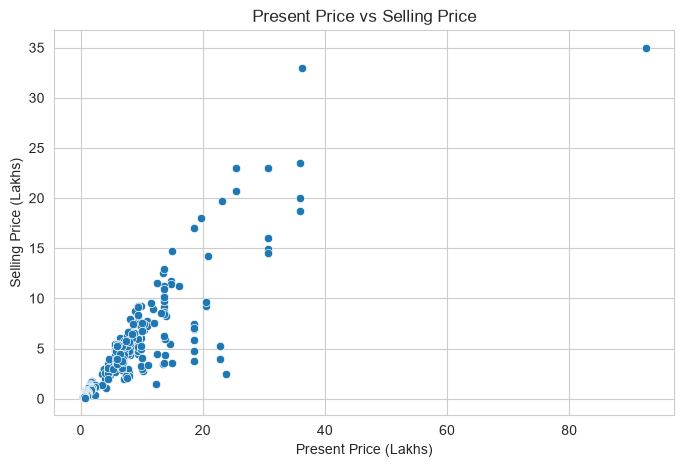

In [17]:
# Selling price vs present price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price"
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price (Lakhs)")
plt.ylabel("Selling Price (Lakhs)")

plt.show()

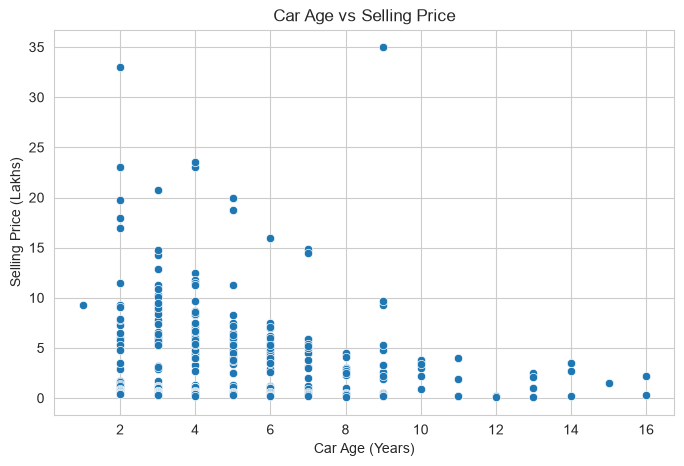

In [18]:
# Selling price vs car age
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price"
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs)")

plt.show()

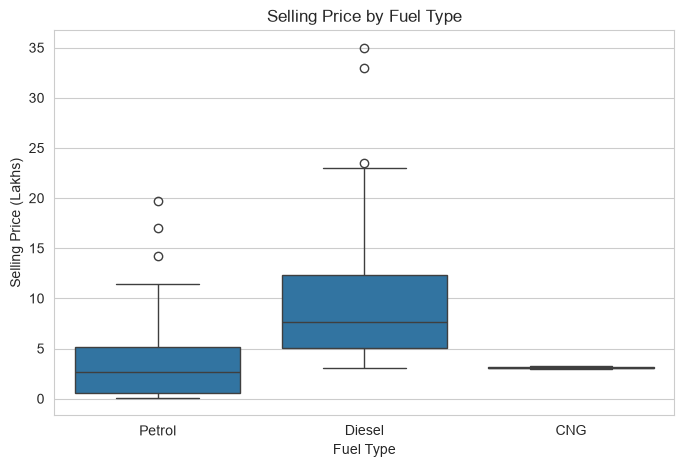

In [19]:
# Selling price by fuel type
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Fuel_Type",
    y="Selling_Price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (Lakhs)")

plt.show()

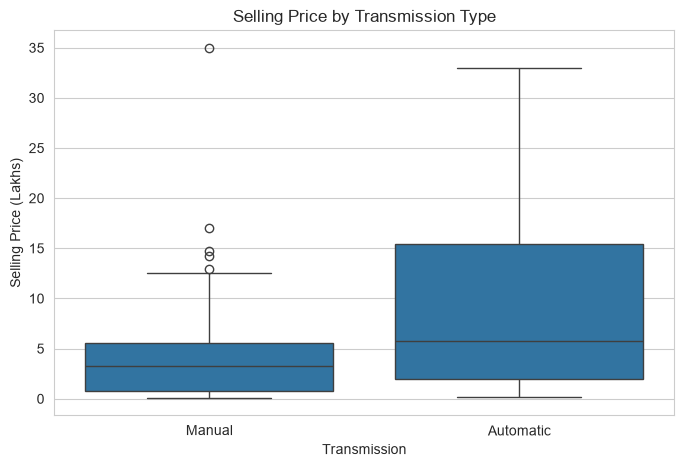

In [20]:
# Selling price by transmission
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Transmission",
    y="Selling_Price"
)

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price (Lakhs)")

plt.show()

## 8. Feature Encoding and Preparation

Machine learning algorithms require numerical inputs.

Our dataset contains categorical features such as:
- Brand
- Fuel_Type
- Seller_Type
- Transmission

We will use One-Hot Encoding to convert these categorical variables into numerical representations.

We will separate the independent variables (X) from the target variable (y).

The target variable is `Selling_Price`.

In [21]:
# Separate features and target
X = df.drop(columns=["Selling_Price"])

y = df["Selling_Price"]

# Identify categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:", categorical_features)

print("\nNumerical features:", numerical_features)

print("\nFeature shape:", X.shape)

print("Target shape:", y.shape)

Categorical features: ['Fuel_Type', 'Seller_Type', 'Transmission', 'Brand']

Numerical features: ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']

Feature shape: (299, 8)
Target shape: (299,)


## 9. Train/Test Split

We divide the dataset into two subsets:

- Training data (80%): Used to train the machine learning models.
- Testing data (20%): Used to evaluate model performance on unseen data.

We use `random_state=42` to make the split reproducible.

Preprocessing will be fitted inside each model pipeline using only the training data, helping prevent data leakage.

In [22]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 8)
Testing features: (60, 8)

Training target: (239,)
Testing target: (60,)


## 10. Model Training

We will train two regression models:

### 1. Linear Regression

Linear Regression predicts a target value by learning the relationship between input features and the target variable.

### 2. Random Forest Regression

Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce predictions.

We will use pipelines to combine preprocessing and model training.

In [23]:
# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

# Linear Regression pipeline
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

print("Models created successfully!")

Models created successfully!


In [24]:
# Train Linear Regression
linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


## 11. Model Evaluation

After training, we evaluate both models using the testing dataset.

We use three evaluation metrics:

### Mean Absolute Error (MAE)

Measures the average absolute difference between actual and predicted prices. Lower values indicate better performance.

### Root Mean Squared Error (RMSE)

Measures prediction errors while giving greater weight to larger errors. Lower values indicate better performance.

### R² Score

Measures how much variation in the target variable is explained by the model. A score closer to 1 generally indicates better performance.

We will compare the two models using these metrics.

In [25]:
# Generate predictions
linear_predictions = linear_model.predict(X_test)

rf_predictions = random_forest_model.predict(X_test)


# Evaluation function
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Evaluate both models
results = pd.DataFrame([
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
])

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.348138,2.388979,0.77856
1,Random Forest,1.399645,3.386566,0.55501


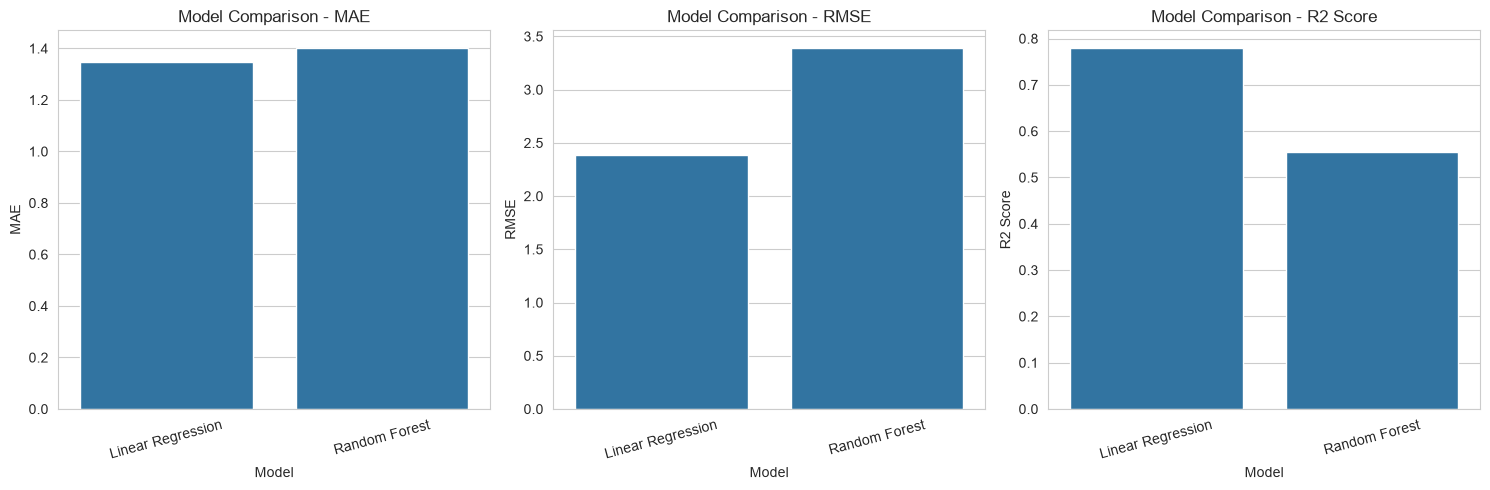

In [26]:
# Visual comparison of model performance
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["MAE", "RMSE", "R2 Score"]

for metric, ax in zip(metrics, axes):

    sns.barplot(
        data=results,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

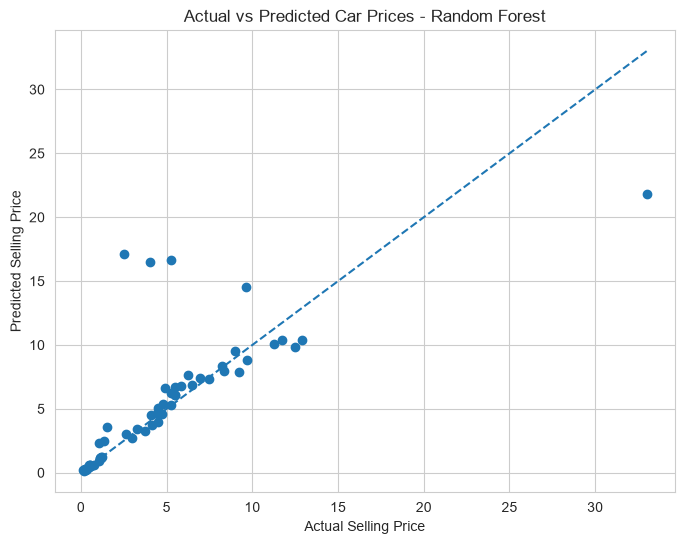

In [27]:
# Actual vs predicted prices for Random Forest
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions)

# Reference line
min_price = min(y_test.min(), rf_predictions.min())
max_price = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Car Prices - Random Forest")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.show()

## 12. Feature Importance

Feature importance helps us understand which input variables contribute most to the predictions made by the Random Forest model.

We will extract the importance scores and visualize the most influential features.

This helps us understand which characteristics are most useful when predicting used car prices.

In [28]:
# Get trained preprocessing and model components
trained_preprocessor = random_forest_model.named_steps["preprocessor"]

trained_rf = random_forest_model.named_steps["model"]

# Get feature names after encoding
feature_names = trained_preprocessor.get_feature_names_out()

# Extract feature importance
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_rf.feature_importances_
})

# Sort by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
46,remainder__Present_Price,8.885873e-01
49,remainder__Car_Age,6.820442e-02
38,categorical__Brand_land,1.378748e-02
47,remainder__Kms_Driven,1.194174e-02
24,categorical__Brand_corolla,3.342961e-03
5,categorical__Transmission_Automatic,2.825255e-03
6,categorical__Transmission_Manual,2.026750e-03
36,categorical__Brand_innova,1.876305e-03
4,categorical__Seller_Type_Individual,1.495885e-03
23,categorical__Brand_city,9.800769e-04


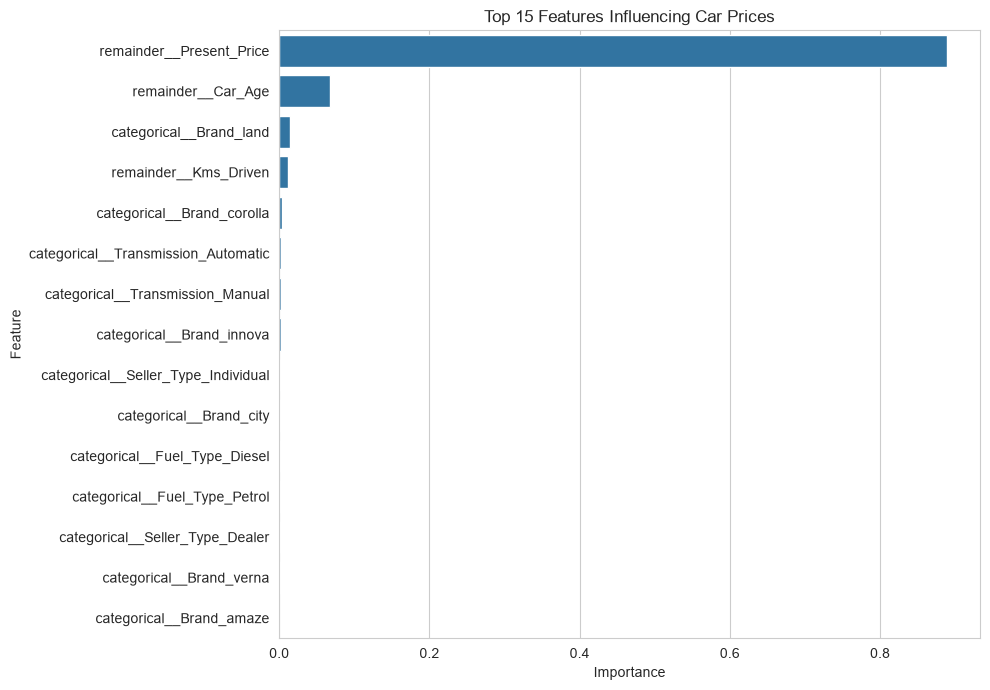

In [29]:
# Visualize feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Car Prices")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 13. Final Model Selection and Saving

We will select the best-performing model based on its test-set RMSE.

The selected model will be saved using Joblib so it can be reused without training it again.

We will also display a sample prediction to demonstrate how the model works.

In [30]:
# Select model with the lowest RMSE
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

best_model_name = results.loc[
    results["RMSE"].idxmin(),
    "Model"
]

best_model = models[best_model_name]

print("Best performing model:", best_model_name)

# Save model
joblib.dump(
    best_model,
    "../models/best_car_price_model.pkl"
)

print("Model saved successfully!")

Best performing model: Linear Regression
Model saved successfully!


In [31]:
# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": best_model.predict(X_test)
})

comparison["Difference"] = (
    comparison["Actual Price"] -
    comparison["Predicted Price"]
)

comparison.head(10)

,Actual Price,Predicted Price,Difference
0,8.99,8.681579,0.308421
1,8.35,8.591651,-0.241651
2,0.45,1.867016,-1.417016
3,7.45,6.708139,0.741861
4,5.25,10.197707,-4.947707
5,5.25,4.715822,0.534178
6,5.85,7.703644,-1.853644
7,1.15,1.903132,-0.753132
8,9.25,8.492123,0.757877
9,0.38,-0.627903,1.007903


## 14. Final Conclusion

In this project, we developed machine learning regression models to predict used car selling prices using the CarDekho dataset.

The project covered:

- Dataset loading and exploration.
- Data cleaning and preprocessing.
- Exploratory Data Analysis and visualization.
- Feature engineering.
- Categorical feature encoding.
- Training Linear Regression and Random Forest models.
- Evaluating model performance using MAE, RMSE, and R².
- Comparing models and identifying important features.
- Saving the best-performing model.

The project demonstrates how supervised machine learning can be applied to a real-world regression problem.

The final model provides predictions based on the characteristics of used cars and helps demonstrate the relationship between vehicle features and their selling prices.

In [32]:
# Load saved model
loaded_model = joblib.load(
    "../models/best_car_price_model.pkl"
)

# Select one test record
sample_car = X_test.iloc[[0]]

# Predict selling price
predicted_price = loaded_model.predict(sample_car)

print("Sample car details:")
display(sample_car)

print("Predicted selling price:", round(predicted_price[0], 2), "Lakhs")
print("Actual selling price:", round(y_test.iloc[0], 2), "Lakhs")

Sample car details:


,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
283,11.8,9010,Petrol,Dealer,Manual,0,city,3


Predicted selling price: 8.68 Lakhs
Actual selling price: 8.99 Lakhs
